In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [24]:
data=pd.read_csv("improved_disease_dataset.csv")

In [25]:
print(data)

      fever  headache  nausea  vomiting  fatigue  joint_pain  skin_rash  \
0         1         0       1         0        1           0          0   
1         0         0       1         0        0           0          1   
2         0         0       1         0        1           0          1   
3         0         0       1         1        1           0          1   
4         1         0       1         0        1           0          0   
...     ...       ...     ...       ...      ...         ...        ...   
1995      1         1       0         0        1           0          0   
1996      1         0       0         0        1           1          1   
1997      1         0       0         1        0           0          0   
1998      0         0       0         0        1           1          0   
1999      0         0       0         1        1           1          0   

      cough  weight_loss  yellow_eyes                       disease  
0         1            1     

In [26]:
from sklearn.preprocessing import LabelEncoder

In [27]:
encode=LabelEncoder()
data["disease"]=encode.fit_transform(data["disease"])
print(data)

      fever  headache  nausea  vomiting  fatigue  joint_pain  skin_rash  \
0         1         0       1         0        1           0          0   
1         0         0       1         0        0           0          1   
2         0         0       1         0        1           0          1   
3         0         0       1         1        1           0          1   
4         1         0       1         0        1           0          0   
...     ...       ...     ...       ...      ...         ...        ...   
1995      1         1       0         0        1           0          0   
1996      1         0       0         0        1           1          1   
1997      1         0       0         1        0           0          0   
1998      0         0       0         0        1           1          0   
1999      0         0       0         1        1           1          0   

      cough  weight_loss  yellow_eyes  disease  
0         1            1            0       29  
1

In [28]:
X=data.iloc[:,:-1]
Y=data.iloc[:,-1]

In [29]:
print(X)
print(Y)

      fever  headache  nausea  vomiting  fatigue  joint_pain  skin_rash  \
0         1         0       1         0        1           0          0   
1         0         0       1         0        0           0          1   
2         0         0       1         0        1           0          1   
3         0         0       1         1        1           0          1   
4         1         0       1         0        1           0          0   
...     ...       ...     ...       ...      ...         ...        ...   
1995      1         1       0         0        1           0          0   
1996      1         0       0         0        1           1          1   
1997      1         0       0         1        0           0          0   
1998      0         0       0         0        1           1          0   
1999      0         0       0         1        1           1          0   

      cough  weight_loss  yellow_eyes  
0         1            1            0  
1         1        

In [30]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter

In [31]:
print("Before",Counter(Y))

Before Counter({29: 90, 20: 80, 16: 80, 24: 80, 7: 70, 17: 70, 34: 70, 10: 70, 37: 70, 6: 70, 33: 70, 21: 70, 26: 60, 13: 60, 28: 60, 14: 60, 8: 50, 31: 50, 35: 50, 22: 50, 5: 50, 4: 50, 18: 40, 23: 40, 1: 40, 12: 40, 30: 40, 32: 40, 11: 40, 9: 40, 36: 40, 15: 40, 19: 40, 27: 30, 3: 30, 25: 30, 0: 30, 2: 10})


In [32]:
print(Y)

0       29
1       29
2       29
3       29
4       29
        ..
1995     2
1996     2
1997     2
1998     2
1999     2
Name: disease, Length: 2000, dtype: int64


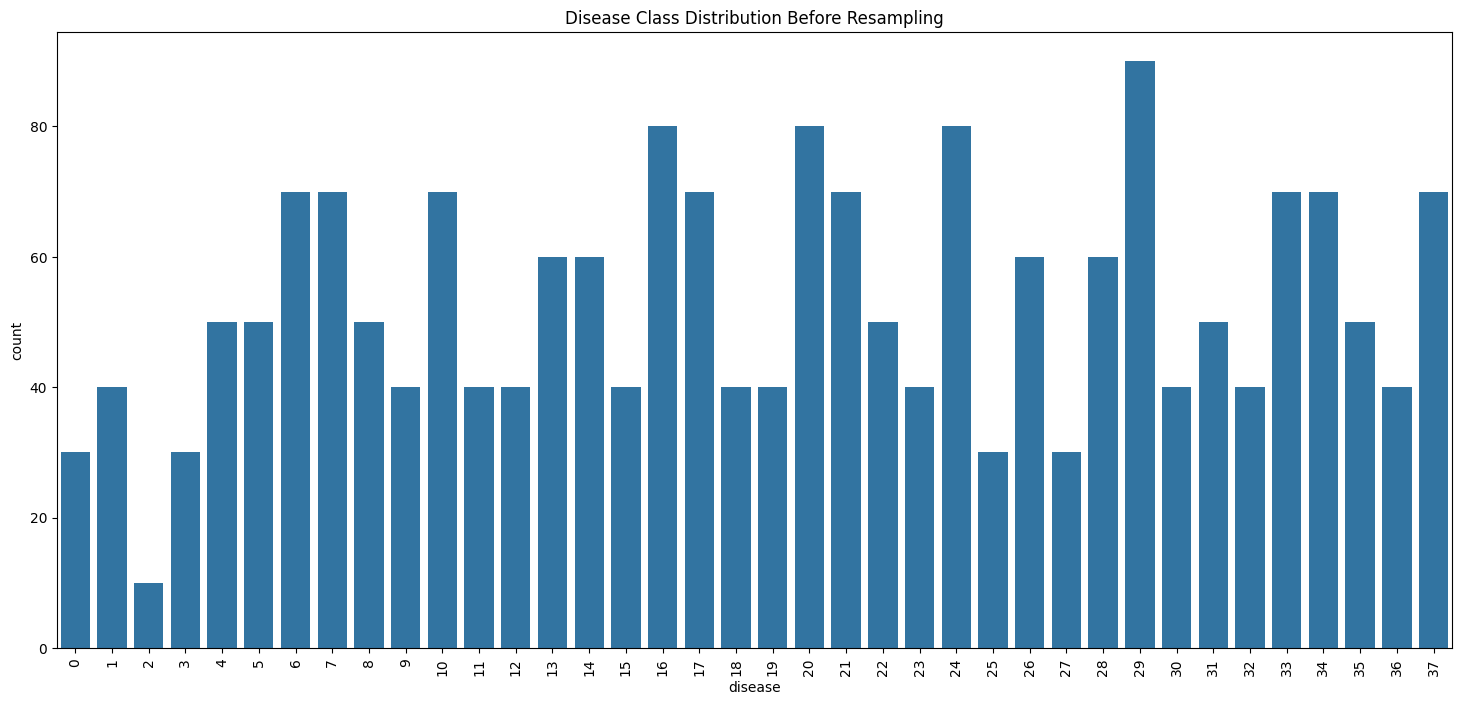

In [33]:


encoder = LabelEncoder()
data["disease"] = encoder.fit_transform(data["disease"])

X = data.iloc[:, :-1]
y = data.iloc[:, -1]

plt.figure(figsize=(18, 8))
sns.countplot(x=y)
plt.title("Disease Class Distribution Before Resampling")
plt.xticks(rotation=90)
plt.show()

ros = RandomOverSampler(random_state=42)
X_resampled, y_resampled = ros.fit_resample(X, y)

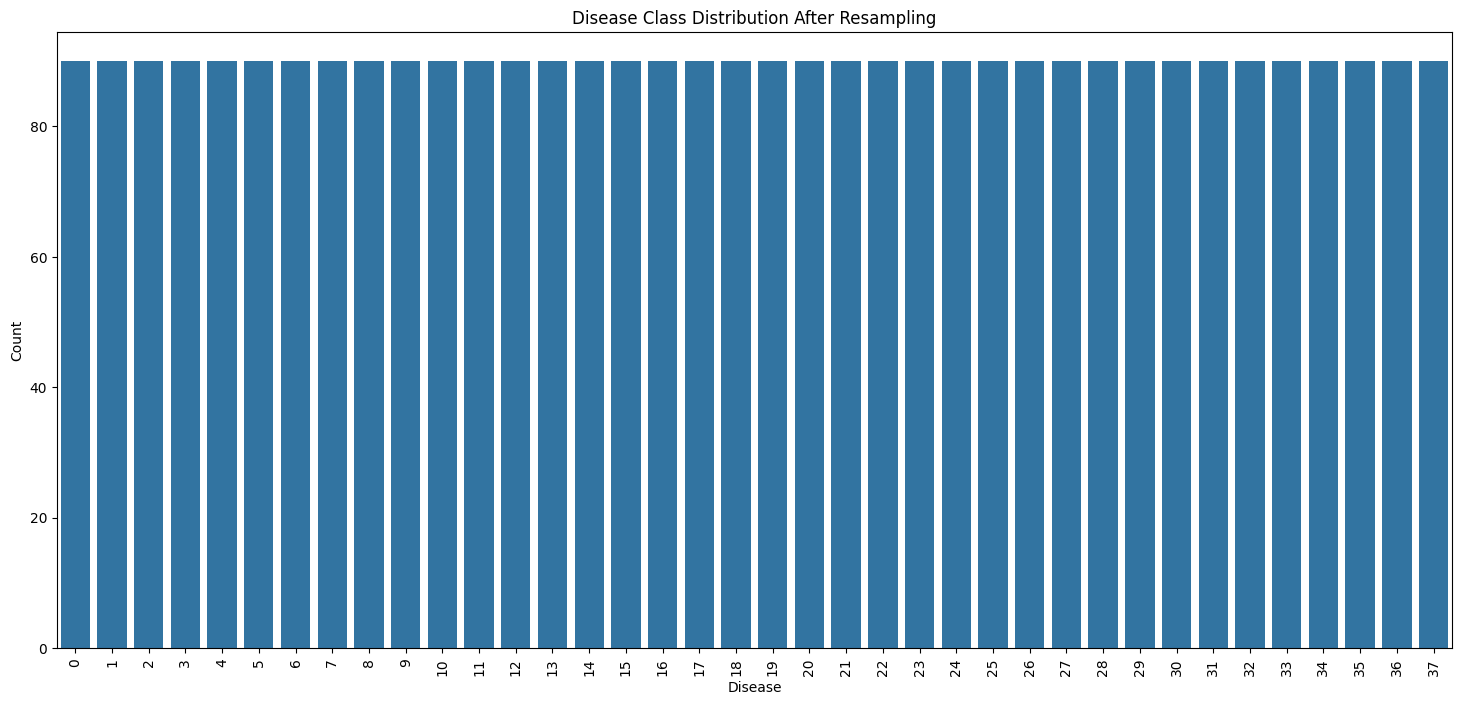

In [34]:
plt.figure(figsize=(18, 8))

sns.countplot(x=y_resampled)

plt.title("Disease Class Distribution After Resampling")
plt.xlabel("Disease")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

In [35]:
X_resampled=X_resampled.fillna(0)

In [36]:
print(X_resampled)

      fever  headache  nausea  vomiting  fatigue  joint_pain  skin_rash  \
0         1         0       1         0        1           0          0   
1         0         0       1         0        0           0          1   
2         0         0       1         0        1           0          1   
3         0         0       1         1        1           0          1   
4         1         0       1         0        1           0          0   
...     ...       ...     ...       ...      ...         ...        ...   
3415      0         0       1         1        0           0          0   
3416      0         0       0         1        0           1          0   
3417      0         0       0         1        0           1          0   
3418      0         0       0         0        0           1          1   
3419      0         1       0         1        1           0          1   

      cough  weight_loss  yellow_eyes  
0         1            1            0  
1         1        

In [37]:
if len(y_resampled.shape)>1:
    y_resampled=y_resampled.values.ravel()

In [38]:
print(y_resampled)

0       29
1       29
2       29
3       29
4       29
        ..
3415    37
3416    37
3417    37
3418    37
3419    37
Name: disease, Length: 3420, dtype: int64


In [39]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [42]:
from sklearn.metrics import accuracy_score,confusion_matrix

In [ ]:
from sklearn.model_selection import train_test_split,cross_val_score,StratifiedKFold

In [41]:
models={"DecisionTree":DecisionTreeClassifier(),
      "RandomForestClassifier":RandomForestClassifier(),
      "SVM":SVC()
}